# 02 · Benchmark
Macro-F1 per model and dataset (`metrics.json`), and the ensemble's confusion matrices (`confusions/`). OOF columns are scenario-held-out over the frozen folds; our_test is our own test set.

In [1]:
import json
from pathlib import Path

import pandas as pd

R = Path("../reports")  # the only directory read (scripts/run_notebooks.py --check-reads-only)


def load(name):
    return json.loads((R / name).read_text(encoding="utf-8"))
m = load("metrics.json")
b = pd.DataFrame(m["benchmark"])
for target in ("category", "priority"):
    t = b[b.target == target].pivot(index="model", columns="dataset", values="macro_f1")
    display(t.round(3).fillna("-"))

dataset,oof_all,oof_official,our_test,our_test_set1,our_test_set2,our_test_set3,our_test_set4
model,,,,,,,
Ensemble (tier 0),0.935,0.935,0.769,0.8,0.828,0.731,0.751
Ensemble + router,-,-,-,-,-,-,-
LLM zero-shot (M4),-,-,-,-,-,-,-
M1,0.205,0.205,0.562,0.586,0.56,0.54,0.547
M2-LR,0.613,0.613,0.766,0.668,0.774,0.778,0.788
M2-kNN,0.464,0.464,0.634,0.663,0.597,0.598,0.651
M2-proto,0.935,0.935,0.767,0.8,0.815,0.731,0.751
M3,-,-,-,-,-,-,-


dataset,oof_all,oof_official,our_test,our_test_set1,our_test_set2,our_test_set3,our_test_set4
model,,,,,,,
Ensemble (tier 0),0.904,0.904,0.752,0.782,0.809,0.793,0.676
Ensemble + router,-,-,-,-,-,-,-
LLM zero-shot (M4),-,-,-,-,-,-,-
M1,0.542,0.542,0.481,0.638,0.43,0.465,0.437
M2-LR,0.651,0.651,0.592,0.665,0.606,0.581,0.511
M2-kNN,0.396,0.396,0.396,0.605,0.414,0.363,0.271
M2-proto,-,-,-,-,-,-,-
M3,-,-,-,-,-,-,-


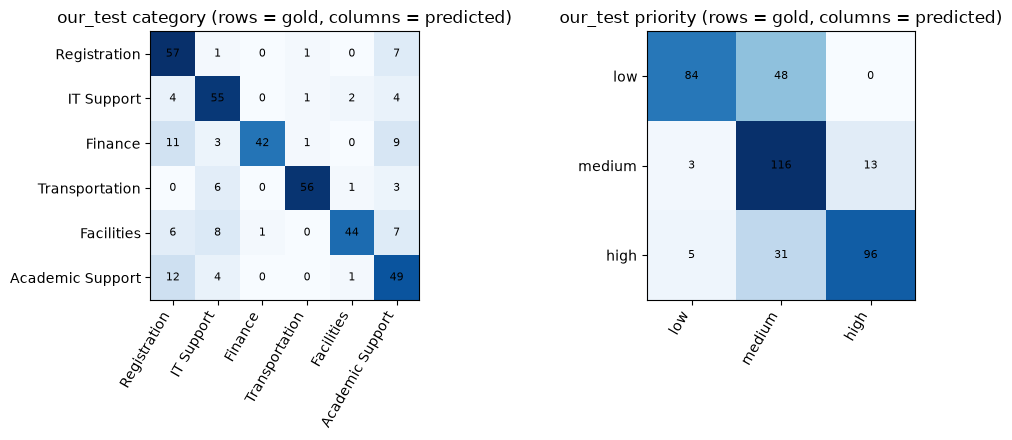

In [2]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, target in zip(axes, ("category", "priority"), strict=True):
    c = load(f"confusions/ensemble_{target}_our_test.json")
    mat = np.array(c["matrix"])
    ax.imshow(mat, cmap="Blues")
    ax.set_xticks(range(len(c["labels"])), c["labels"], rotation=60, ha="right")
    ax.set_yticks(range(len(c["labels"])), c["labels"])
    for i in range(len(mat)):
        for j in range(len(mat)):
            ax.text(j, i, mat[i, j], ha="center", va="center", fontsize=8)
    ax.set_title(f"our_test {target} (rows = gold, columns = predicted)")
plt.tight_layout()
plt.show()